---

Reconecte ao Drive.

In [1]:
import os
from pathlib import Path

In [2]:
DRIVE_DIRECTORY = Path.cwd().parent / "data"

---

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import DBSCAN, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


## Outros algoritmos

### Base de dados cobertura vegetal

Neste exercício você vai usar a base de dados de cobertura vegetal, explorada nos exercícios da **Parte 1 - Classificação**.

Comece carregando os dados do arquivo `cov_types.csv` armazenado na pasta do Drive.

In [4]:
base = pd.read_csv(os.path.join(DRIVE_DIRECTORY, "cov_types.csv"))

In [5]:
base.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,Wilderness_Area,Soil_Type,Cover_Type
0,2767.0,66.0,17.0,210.0,18.0,1190.0,234.0,204.0,96.0,2251.0,2,30,Lodgepole Pine
1,2724.0,160.0,19.0,60.0,4.0,1350.0,236.0,240.0,127.0,2514.0,2,16,Lodgepole Pine
2,2360.0,65.0,7.0,127.0,21.0,1377.0,227.0,226.0,134.0,339.0,3,5,Ponderosa Pine
3,2995.0,45.0,4.0,285.0,30.0,5125.0,221.0,231.0,146.0,5706.0,0,11,Lodgepole Pine
4,2400.0,106.0,27.0,150.0,63.0,342.0,253.0,196.0,51.0,811.0,2,3,Ponderosa Pine


Remova as colunas categóricas, `Wilderness_Area` e `Soil_Type`.

In [6]:
base = base.drop(columns=['Wilderness_Area', 'Soil_Type'])

Separe a coluna com a variável alvo `Cover_Type` em uma variável `y`.

In [7]:
y = base['Cover_Type'].values

Separe as demais colunas em uma variável `X`, no formato de NumPy array.

In [8]:
X = base.drop(columns=['Cover_Type']).values

Escalone os valores de `X` utilizando `StandardScaler`.

In [9]:
scaler =  StandardScaler()
X = scaler.fit_transform(X)

Agora gere um dendograma de `X`, utilizando `method=ward`. Exiba o dendrograma gerado.

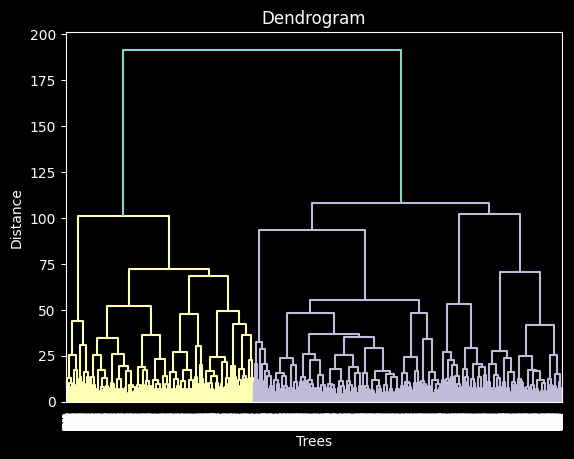

In [10]:
dendrogram = dendrogram(linkage(X, method="ward"))
plt.title("Dendrogram")
plt.xlabel("Trees")
plt.ylabel("Distance")
plt.show()

Agrupe os dados com `AgglomerativeClustering`, utilizando `n_clusters=7`,  `metric="euclidean"` e `linkage="ward"`. Recupere os rótulos com `fit_predict`.

In [11]:
agg = AgglomerativeClustering(n_clusters=7, linkage="ward", metric='euclidean')
labels = agg.fit_predict(X)

Vamos visualizar os dados junto com os rótulos gerados. Comece transformando `X` com a técnica de PCA, utilizando 2 componentes.

In [14]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

Plote o PCA, utilizando como argumento para cor os rótulos gerados pelo algoritmo, no formato de string.

In [15]:
fig = px.scatter(x=X_pca[:,0], y=X_pca[:, 1], color=labels.astype(str))
fig.show()

Compare os rótulos gerados com as classes originais.

In [16]:
pd.crosstab(labels, y)

col_0,Aspen,Cottonwood/Willow,Douglas-fir,Krummholz,Lodgepole Pine,Ponderosa Pine,Spruce/Fir
row_0,,,,,,,
0,8,0,0,25,820,0,655
1,10,1,13,95,866,32,697
2,78,30,111,108,1740,222,1108
3,18,0,2,66,384,18,432
4,0,3,92,9,136,152,102
5,19,13,26,24,133,72,90
6,30,8,34,35,768,85,630


Novamente, se vê pouca correlação entre os rótulos.

Agora treine um algoritmo DBSCAN, com `eps=0.95` e `min_samples=2`.

In [17]:
dbscan = DBSCAN(eps=0.95, min_samples=2)
dbscan.fit(X)

,"eps eps: float, default=0.5The maximum distance between two samples for one to be consideredas in the neighborhood of the other. This is not a maximum boundon the distances of points within a cluster. This is the mostimportant DBSCAN parameter to choose appropriately for your data setand distance function. Smaller values generally lead to more clusters.",0.95
,"min_samples min_samples: int, default=5The number of samples (or total weight) in a neighborhood for a point tobe considered as a core point. This includes the point itself. If`min_samples` is set to a higher value, DBSCAN will find denser clusters,whereas if it is set to a lower value, the found clusters will be moresparse.",2
,"metric metric: str, or callable, default='euclidean'The metric to use when calculating distance between instances in afeature array. If metric is a string or callable, it must be one ofthe options allowed by :func:`sklearn.metrics.pairwise_distances` forits metric parameter.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors for DBSCAN... versionadded:: 0.17 metric *precomputed* to accept precomputed sparse matrix.",'euclidean'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function... versionadded:: 0.19",None
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'The algorithm to be used by the NearestNeighbors moduleto compute pointwise distances and find nearest neighbors.'auto' will attempt to decide the most appropriate algorithmbased on the values passed to :meth:`fit` method.See :class:`~sklearn.neighbors.NearestNeighbors` documentation fordetails.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or cKDTree. This can affect the speedof the construction and query, as well as the memory requiredto store the tree. The optimal value dependson the nature of the problem.",30
,"p p: float, default=NoneThe power of the Minkowski metric to be used to calculate distancebetween points. If None, then ``p=2`` (equivalent to the Euclideandistance). When p=1, this is equivalent to Manhattan distance.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None


Recupere os rótulos e exiba o gráfico de PCA.

In [18]:
labels = dbscan.labels_

In [ ]:
labels

array([0, 0, 0, ..., 0, 0, 0], shape=(10000,))

Veja que este algoritmo não utiliza o número de grupos como argumento, então ele pode gerar tantos grupos quanto julgue necessário. Além disso, ele cria um grupo chamado `-1` com os dados que ele considera que não fazem parte de nenhum grupo.